# Session 6: Analysis of Variance (ANOVA and MANOVA)

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    pass  # numpy, pandas, scipy, statsmodels and matplotlib are preinstalled in Colab
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/03-inferential-statistical-analysis/code/'
    for f in []:
        if not os.path.exists(f):
            subprocess.run(['wget', '-q', base + f], check=False)
print('ready')

ready


## Example: `session-06_one_way_anova.py`

In [2]:
"""
Session 6 · Example 1: One-way ANOVA (one-way classification), by hand
---------------------------------------------------------------------
Three teaching methods were used with three groups of students. Do the mean
test scores differ?  H0: mu_lecture = mu_flipped = mu_project

We build the full ANOVA table by hand:
   SST (total) = SSB (between groups) + SSW (within groups)
   MSB = SSB / (k - 1),  MSW = SSW / (N - k),  F = MSB / MSW
then check it with scipy.stats.f_oneway, test the assumptions, compute eta
squared, and save a box plot: session-06_one_way_anova.png

Run:  python session-06_one_way_anova.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

groups = {
    "Lecture": np.array([62, 58, 65, 60, 63, 59, 61, 64]),
    "Flipped": np.array([70, 68, 74, 71, 66, 72, 69, 73]),
    "Project": np.array([66, 63, 70, 65, 68, 62, 67, 64]),
}
allx = np.concatenate(list(groups.values()))
N, k, grand = len(allx), len(groups), allx.mean()

print("Group means:", {g: round(float(x.mean()), 2) for g, x in groups.items()}, f" grand mean = {grand:.3f}")
SSB = sum(len(x) * (x.mean() - grand) ** 2 for x in groups.values())
SSW = sum(((x - x.mean()) ** 2).sum() for x in groups.values())
SST = ((allx - grand) ** 2).sum()
dfb, dfw = k - 1, N - k
MSB, MSW = SSB / dfb, SSW / dfw
F = MSB / MSW
p = stats.f.sf(F, dfb, dfw)

print("\nANOVA table")
print(f"{'Source':<16}{'SS':>10}{'df':>5}{'MS':>10}{'F':>9}{'p':>11}")
print(f"{'Between groups':<16}{SSB:>10.3f}{dfb:>5}{MSB:>10.3f}{F:>9.3f}{p:>11.2e}")
print(f"{'Within groups':<16}{SSW:>10.3f}{dfw:>5}{MSW:>10.3f}")
print(f"{'Total':<16}{SST:>10.3f}{N - 1:>5}")
print(f"Check: SSB + SSW = {SSB + SSW:.3f} = SST")
print(f"Critical F(0.95; {dfb}, {dfw}) = {stats.f.ppf(0.95, dfb, dfw):.3f}")
print("scipy f_oneway:", tuple(round(float(v), 6) for v in stats.f_oneway(*groups.values())))

eta2 = SSB / SST
print(f"\nEffect size eta^2 = SSB/SST = {eta2:.3f} -> {100 * eta2:.0f}% of score variation is explained by method")
print("Assumptions:")
for g, x in groups.items():
    print(f"   Shapiro-Wilk {g:<8} p = {stats.shapiro(x).pvalue:.3f}")
print(f"   Levene (equal variances) p = {stats.levene(*groups.values()).pvalue:.3f}")
print(f"Non-parametric check: Kruskal-Wallis p = {stats.kruskal(*groups.values()).pvalue:.5f}")

fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot(list(groups.values()), patch_artist=True, medianprops=dict(color="#0A0716"))
for patch, c in zip(bp["boxes"], ["#A78BFA", "#FF6B1A", "#FCD34D"]):
    patch.set_facecolor(c)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(list(groups))
ax.axhline(grand, color="#F43F5E", ls="--", label=f"grand mean {grand:.1f}")
ax.set_ylabel("test score"); ax.set_title(f"One-way ANOVA: F = {F:.1f}, p = {p:.1e}"); ax.legend()
fig.tight_layout(); fig.savefig("session-06_one_way_anova.png", dpi=100)
print("Saved chart: session-06_one_way_anova.png")

Group means: {'Lecture': 61.5, 'Flipped': 70.38, 'Project': 65.62}  grand mean = 65.833

ANOVA table
Source                  SS   df        MS        F          p
Between groups     315.583    2   157.792   23.377   4.56e-06
Within groups      141.750   21     6.750
Total              457.333   23
Check: SSB + SSW = 457.333 = SST
Critical F(0.95; 2, 21) = 3.467
scipy f_oneway: (23.376543, 5e-06)

Effect size eta^2 = SSB/SST = 0.690 -> 69% of score variation is explained by method
Assumptions:
   Shapiro-Wilk Lecture  p = 0.933
   Shapiro-Wilk Flipped  p = 0.978
   Shapiro-Wilk Project  p = 0.978
   Levene (equal variances) p = 0.977
Non-parametric check: Kruskal-Wallis p = 0.00031
Saved chart: session-06_one_way_anova.png


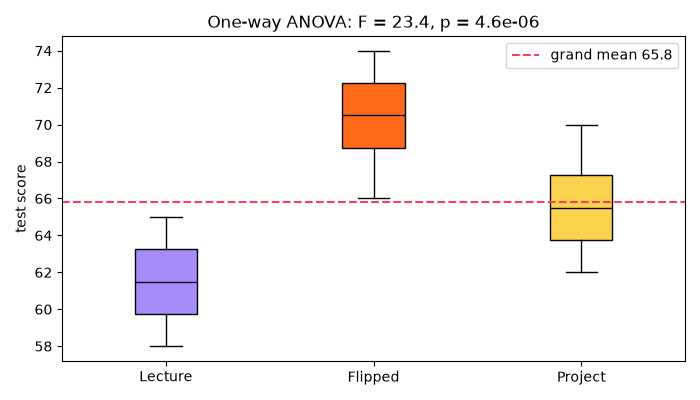

In [3]:
from IPython.display import Image, display
display(Image(filename='session-06_one_way_anova.png'))  # chart saved by the cell above

## Example: `session-06_tukey_posthoc.py`

In [4]:
"""
Session 6 · Example 2: Which groups differ? Post-hoc tests after ANOVA
---------------------------------------------------------------------
A significant ANOVA only says 'not all means are equal'. Post-hoc tests find
WHICH pairs differ while controlling the family-wise error rate.
  1. Why not just run three t tests? (simulation of the inflated error)
  2. Tukey's HSD with statsmodels
  3. Bonferroni-corrected pairwise t tests for comparison

Run:  python session-06_tukey_posthoc.py
"""
from itertools import combinations
import numpy as np
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

groups = {
    "Lecture": np.array([62, 58, 65, 60, 63, 59, 61, 64]),
    "Flipped": np.array([70, 68, 74, 71, 66, 72, 69, 73]),
    "Project": np.array([66, 63, 70, 65, 68, 62, 67, 64]),
}

# 1. Multiple t tests inflate the Type I error: 5 identical groups -> 10 pairwise tests
rng = np.random.default_rng(4)
false_alarm = 0
for _ in range(2000):
    g = rng.normal(60, 5, size=(5, 10))
    if any(stats.ttest_ind(g[i], g[j]).pvalue < 0.05 for i, j in combinations(range(5), 2)):
        false_alarm += 1
print(f"1) 5 identical groups, 10 t tests at 0.05: at least one false 'difference' in "
      f"{false_alarm / 20:.1f}% of studies (ANOVA keeps it at 5%)")

# 2. Tukey HSD
scores = np.concatenate(list(groups.values()))
labels = np.repeat(list(groups), [len(v) for v in groups.values()])
tukey = pairwise_tukeyhsd(scores, labels, alpha=0.05)
print("\n2) Tukey HSD")
print(tukey.summary())

# 3. Bonferroni
pairs = list(combinations(groups, 2))
print(f"\n3) Bonferroni: compare each p with 0.05/{len(pairs)} = {0.05 / len(pairs):.4f}")
for a, b in pairs:
    p = stats.ttest_ind(groups[a], groups[b]).pvalue
    print(f"   {a} vs {b}: p = {p:.5f}, adjusted p = {min(1, p * len(pairs)):.5f} "
          f"-> {'different' if p < 0.05 / len(pairs) else 'not different'}")

1) 5 identical groups, 10 t tests at 0.05: at least one false 'difference' in 28.8% of studies (ANOVA keeps it at 5%)



2) Tukey HSD
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
Flipped Lecture   -8.875    0.0 -12.1493 -5.6007   True
Flipped Project    -4.75  0.004  -8.0243 -1.4757   True
Lecture Project    4.125 0.0121   0.8507  7.3993   True
-------------------------------------------------------

3) Bonferroni: compare each p with 0.05/3 = 0.0167
   Lecture vs Flipped: p = 0.00001, adjusted p = 0.00002 -> different
   Lecture vs Project: p = 0.00616, adjusted p = 0.01849 -> different
   Flipped vs Project: p = 0.00314, adjusted p = 0.00943 -> different


## Example: `session-06_two_way_anova.py`

In [5]:
"""
Session 6 · Example 3: Two-way ANOVA (two-way classification) with interaction
-----------------------------------------------------------------------------
Crop yield (kg per plot) for 3 fertilisers x 2 irrigation methods, 4 plots per
combination. Two-way ANOVA tests:
   * main effect of fertiliser
   * main effect of irrigation
   * the INTERACTION (does the best fertiliser depend on irrigation?)
Also shown: two-way ANOVA WITHOUT replication (one value per cell, no
interaction term), and an interaction plot: session-06_two_way_anova.png

Run:  python session-06_two_way_anova.py
"""
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

rows = []
cell_means = {("F1", "Drip"): 30, ("F2", "Drip"): 36, ("F3", "Drip"): 34,
              ("F1", "Flood"): 28, ("F2", "Flood"): 29, ("F3", "Flood"): 35}
offsets = [-1.5, 0.5, 1.2, -0.2]                 # fixed within-cell variation (deterministic)
for (fert, irr), m in cell_means.items():
    for i, o in enumerate(offsets):
        rows.append({"fertiliser": fert, "irrigation": irr, "yield_kg": m + o + 0.3 * (i % 2)})
df = pd.DataFrame(rows)

print("Cell means (kg):")
print(df.pivot_table(values="yield_kg", index="fertiliser", columns="irrigation", aggfunc="mean").round(2).to_string())

model = smf.ols("yield_kg ~ C(fertiliser) * C(irrigation)", data=df).fit()
table = sm.stats.anova_lm(model, typ=2)
table["eta_sq"] = table["sum_sq"] / table["sum_sq"].sum()
print("\nTwo-way ANOVA with interaction (Type II sums of squares)")
print(table.assign(**{"PR(>F)": lambda t: t["PR(>F)"].map(lambda v: "" if v != v else f"{v:.2e}")}).round(4).to_string())

# Without replication: one observation per cell (e.g. 4 shops x 3 weeks of sales)
sales = pd.DataFrame({"shop": np.repeat(["S1", "S2", "S3", "S4"], 3),
                      "week": ["W1", "W2", "W3"] * 4,
                      "sales": [52, 58, 61, 47, 50, 56, 60, 66, 70, 45, 49, 53]})
m2 = smf.ols("sales ~ C(shop) + C(week)", data=sales).fit()
print("\nTwo-way ANOVA without replication (no interaction term possible)")
print(sm.stats.anova_lm(m2, typ=2).assign(**{"PR(>F)": lambda t: t["PR(>F)"].map(lambda v: "" if v != v else f"{v:.2e}")}).round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
means = df.groupby(["fertiliser", "irrigation"]).yield_kg.mean().unstack()
for irr, c in zip(means.columns, ["#FF6B1A", "#A78BFA"]):
    ax.plot(means.index, means[irr], marker="o", color=c, lw=2, label=irr)
ax.set_xlabel("fertiliser"); ax.set_ylabel("mean yield (kg)")
ax.set_title("Interaction plot: crossing lines = interaction"); ax.legend(title="irrigation"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("session-06_two_way_anova.png", dpi=100)
print("Saved chart: session-06_two_way_anova.png")

Cell means (kg):
irrigation   Drip  Flood
fertiliser              
F1          30.15  28.15
F2          36.15  29.15
F3          34.15  35.15

Two-way ANOVA with interaction (Type II sums of squares)
                               sum_sq    df        F    PR(>F)  eta_sq
C(fertiliser)                124.0000   2.0  43.7647  1.22e-07  0.4816
C(irrigation)                 42.6667   1.0  30.1176  3.27e-05  0.1657
C(fertiliser):C(irrigation)   65.3333   2.0  23.0588  1.08e-05  0.2537
Residual                      25.5000  18.0      NaN            0.0990

Two-way ANOVA without replication (no interaction term possible)
            sum_sq   df         F    PR(>F)
C(shop)   484.2500  3.0  215.2222  1.70e-06
C(week)   162.1667  2.0  108.1111  1.97e-05
Residual    4.5000  6.0       NaN          
Saved chart: session-06_two_way_anova.png


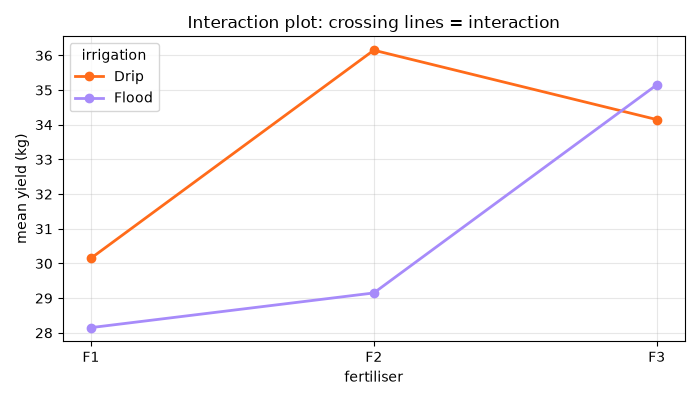

In [6]:
from IPython.display import Image, display
display(Image(filename='session-06_two_way_anova.png'))  # chart saved by the cell above

## Example: `session-06_manova.py`

In [7]:
"""
Session 6 · Example 4: MANOVA - several outcomes at once
-------------------------------------------------------
Three study programmes are compared on TWO outcomes measured on the same
students: exam score and project score. MANOVA tests whether the vector of
means (exam, project) differs between programmes, using the correlation
between the outcomes. We report Wilks' lambda, Pillai's trace and friends,
then follow up with one univariate ANOVA per outcome.

Run:  python session-06_manova.py
"""
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.multivariate.manova import MANOVA

rng = np.random.default_rng(17)
centres = {"Evening": (62, 70), "Weekend": (64, 64), "Regular": (70, 72)}
cov = [[25, 12], [12, 25]]                         # exam and project scores are correlated
frames = []
for prog, mu in centres.items():
    xy = rng.multivariate_normal(mu, cov, size=15).round(1)
    frames.append(pd.DataFrame({"programme": prog, "exam": xy[:, 0], "project": xy[:, 1]}))
df = pd.concat(frames, ignore_index=True)

print("Means by programme")
print(df.groupby("programme")[["exam", "project"]].mean().round(2).to_string())
print(f"Correlation between exam and project: {df.exam.corr(df.project):.2f}")

mv = MANOVA.from_formula("exam + project ~ programme", data=df)
res = mv.mv_test()
stat = res.results["programme"]["stat"]
print("\nMANOVA (effect: programme)")
print(stat.round(4).to_string())

print("\nFollow-up univariate ANOVAs")
for dv in ["exam", "project"]:
    t = sm.stats.anova_lm(smf.ols(f"{dv} ~ C(programme)", data=df).fit(), typ=2)
    print(f"   {dv:<8} F = {t.loc['C(programme)', 'F']:.3f}, p = {t.loc['C(programme)', 'PR(>F)']:.5f}")

Means by programme
            exam  project
programme                
Evening    64.17    72.43
Regular    70.07    73.64
Weekend    65.76    64.25
Correlation between exam and project: 0.51

MANOVA (effect: programme)
                           Value Num DF     Den DF    F Value    Pr > F
Wilks' lambda           0.480694      4       82.0    9.06782  0.000004
Pillai's trace           0.60498    4.0       84.0   9.107097  0.000004
Hotelling-Lawley trace  0.902093      4  48.179104   9.176331  0.000014
Roy's greatest root      0.60983      2         42  12.806422  0.000045

Follow-up univariate ANOVAs
   exam     F = 6.229, p = 0.00427
   project  F = 9.893, p = 0.00030


## Example: `session-06_problem_delivery_zones.py`

In [8]:
"""
Session 6 · Real-life problem: do delivery times differ by zone and time of day?
-------------------------------------------------------------------------------
PROBLEM
A food-delivery start-up in Karachi recorded delivery times (minutes) for
orders in 4 zones (Clifton, Gulshan, Saddar, North Nazimabad) at 2 times of
day (Lunch, Dinner), 6 orders per combination (48 orders).
Operations wants to know:
  1. Do mean delivery times differ by zone? (one-way ANOVA + Tukey)
  2. Does time of day matter, and does its effect depend on the zone? (two-way ANOVA)
  3. Are the assumptions reasonable? (Levene, Shapiro on residuals)
  4. Which zone-time combinations need extra riders?

Run:  python session-06_problem_delivery_zones.py
"""
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

rng = np.random.default_rng(99)
base = {"Clifton": 28, "Gulshan": 34, "Saddar": 38, "North Nazimabad": 33}
dinner_extra = {"Clifton": 2, "Gulshan": 3, "Saddar": 9, "North Nazimabad": 3}   # Saddar traffic at night
rows = [{"zone": z, "time": t, "minutes": round(base[z] + (dinner_extra[z] if t == "Dinner" else 0)
                                              + rng.normal(0, 3), 1)}
        for z in base for t in ["Lunch", "Dinner"] for _ in range(6)]
df = pd.DataFrame(rows)

print("Mean minutes by zone and time")
print(df.pivot_table(values="minutes", index="zone", columns="time", aggfunc="mean").round(1).to_string())

# 1. One-way ANOVA by zone + Tukey
f1 = stats.f_oneway(*[g.minutes for _, g in df.groupby("zone")])
print(f"\n1) One-way ANOVA by zone: F = {f1.statistic:.2f}, p = {f1.pvalue:.2e}")
print(pairwise_tukeyhsd(df.minutes, df.zone).summary())

# 2. Two-way ANOVA with interaction
model = smf.ols("minutes ~ C(zone) * C(time)", data=df).fit()
print("\n2) Two-way ANOVA")
print(sm.stats.anova_lm(model, typ=2).assign(**{"PR(>F)": lambda t: t["PR(>F)"].map(lambda v: "" if v != v else f"{v:.2e}")}).round(4).to_string())

# 3. Assumptions
print(f"\n3) Levene across the 8 cells p = {stats.levene(*[g.minutes for _, g in df.groupby(['zone', 'time'])]).pvalue:.3f}; "
      f"Shapiro on residuals p = {stats.shapiro(model.resid).pvalue:.3f}")

# 4. Action list: cells more than 3 minutes above the overall mean
cells = df.groupby(["zone", "time"]).minutes.mean()
overall = df.minutes.mean()
print(f"\n4) Overall mean {overall:.1f} min. Cells that need extra riders (> mean + 3 min):")
for (z, t), m in cells.items():
    if m > overall + 3:
        print(f"   {z} at {t}: {m:.1f} min")

Mean minutes by zone and time
time             Dinner  Lunch
zone                          
Clifton            30.4   28.2
Gulshan            37.5   34.8
North Nazimabad    37.4   33.9
Saddar             48.9   37.8

1) One-way ANOVA by zone: F = 23.20, p = 3.69e-09


         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1          group2     meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------
        Clifton         Gulshan   6.8917  0.001  2.3895 11.3939   True
        Clifton North Nazimabad   6.4083 0.0024  1.9061 10.9105   True
        Clifton          Saddar    14.05    0.0  9.5478 18.5522   True
        Gulshan North Nazimabad  -0.4833 0.9917 -4.9855  4.0189  False
        Gulshan          Saddar   7.1583 0.0006  2.6561 11.6605   True
North Nazimabad          Saddar   7.6417 0.0003  3.1395 12.1439   True
----------------------------------------------------------------------

2) Two-way ANOVA
                    sum_sq    df        F    PR(>F)
C(zone)          1187.5042   3.0  51.6037  8.18e-14
C(time)           286.1633   1.0  37.3062  3.33e-07
C(zone):C(time)   157.6450   3.0   6.8506  7.83e-04
Residual          306.8267  40.0      NaN          

3) Levene a

## Example: `session-06_project_experiment_report.py`

In [9]:
"""
Session 6 · Mini project: a one-click ANOVA experiment report
------------------------------------------------------------
Give the function a DataFrame, an outcome column and one or two factor
columns. It produces a complete, publication-style report:
  * descriptive table (n, mean, sd per group)
  * assumption checks (Levene, Shapiro-Wilk on residuals)
  * one-way or two-way ANOVA table with eta squared
  * automatic switch to Welch's ANOVA or Kruskal-Wallis when assumptions fail
  * Tukey HSD for significant one-way results
  * a plain-English conclusion
Demonstrated on (a) a website-layout experiment and (b) a fertiliser x soil trial.

Run:  python session-06_project_experiment_report.py
"""
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway


def anova_report(df, outcome, factors, alpha=0.05):
    print("=" * 70)
    print(f"Outcome: {outcome}   Factor(s): {', '.join(factors)}   N = {len(df)}")
    desc = df.groupby(factors)[outcome].agg(["count", "mean", "std"]).round(2)
    print(desc.to_string())
    formula = f"{outcome} ~ " + " * ".join(f"C({f})" for f in factors)
    model = smf.ols(formula, data=df).fit()
    groups = [g[outcome].values for _, g in df.groupby(factors)]
    lev_p = stats.levene(*groups).pvalue
    sh_p = stats.shapiro(model.resid).pvalue
    print(f"Assumptions: Levene p = {lev_p:.3f} ({'ok' if lev_p > alpha else 'unequal variances'}), "
          f"Shapiro residuals p = {sh_p:.3f} ({'ok' if sh_p > alpha else 'not normal'})")

    if len(factors) == 1 and sh_p <= alpha:
        r = stats.kruskal(*groups)
        print(f"Kruskal-Wallis H = {r.statistic:.3f}, p = {r.pvalue:.4g}")
        sig = r.pvalue < alpha
    elif len(factors) == 1 and lev_p <= alpha:
        r = anova_oneway(df[outcome], df[factors[0]], use_var="unequal")
        print(f"Welch's ANOVA F = {r.statistic:.3f}, p = {r.pvalue:.4g}")
        sig = r.pvalue < alpha
    else:
        table = sm.stats.anova_lm(model, typ=2)
        table["eta_sq"] = table["sum_sq"] / table["sum_sq"].sum()
        print(table.assign(**{"PR(>F)": lambda t: t["PR(>F)"].map(lambda v: "" if v != v else f"{v:.2e}")}).round(4).to_string())
        sig = (table["PR(>F)"].dropna() < alpha).any()
    if len(factors) == 1 and sig:
        print(pairwise_tukeyhsd(df[outcome], df[factors[0]], alpha=alpha).summary())

    # plain-English conclusion
    best = desc["mean"].idxmax()
    print("Conclusion:", f"at least one group differs (alpha = {alpha}); highest mean: {best}"
          if sig else "no significant differences between groups were found.")


rng = np.random.default_rng(2024)
# (a) minutes spent on a course website with three page layouts
layout = pd.DataFrame({
    "layout": np.repeat(["Classic", "Cards", "Video-first"], 20),
    "minutes": np.r_[rng.normal(6.0, 1.5, 20), rng.normal(7.4, 1.5, 20), rng.normal(7.0, 1.5, 20)].round(2),
})
anova_report(layout, "minutes", ["layout"])

# (b) wheat yield for 2 fertilisers x 3 soil types, 5 plots each
soil_effect = {"Clay": 0, "Loam": 4, "Sandy": -3}
trial = pd.DataFrame([{"fertiliser": f, "soil": s,
                       "yield_kg": 40 + soil_effect[s] + (3 if f == "Organic" and s == "Sandy" else 0)
                       + (2 if f == "Urea" else 0) + rng.normal(0, 1.5)}
                      for f in ["Urea", "Organic"] for s in soil_effect for _ in range(5)])
anova_report(trial, "yield_kg", ["fertiliser", "soil"])

Outcome: minutes   Factor(s): layout   N = 60
             count  mean   std
layout                        
Cards           20  7.44  1.19
Classic         20  6.20  1.61
Video-first     20  7.05  1.51
Assumptions: Levene p = 0.196 (ok), Shapiro residuals p = 0.529 (ok)
             sum_sq    df       F    PR(>F)  eta_sq
C(layout)   15.9052   2.0  3.7934  2.84e-02  0.1175
Residual   119.4967  57.0     NaN            0.8825
   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1    group2   meandiff p-adj   lower   upper  reject
----------------------------------------------------------
  Cards     Classic   -1.233 0.0248 -2.3348 -0.1312   True
  Cards Video-first   -0.387 0.6767 -1.4888  0.7148  False
Classic Video-first    0.846 0.1635 -0.2558  1.9478  False
----------------------------------------------------------
Conclusion: at least one group differs (alpha = 0.05); highest mean: Cards
Outcome: yield_kg   Factor(s): fertiliser, soil   N = 30
                  count   mea